# First Passage Time Simulation

## Introduction

The goal of this Jupyter notebook is to create a faster, more accurate, and more versatile version of the first passage time simulation for various graphs from the paper

> **Vertex Centrality Reconstruction in an Inverse Problem for Information Diffusion**
> Yixian Gao, Songshuo Li, and Yang Yang (arXiv:2603.20710, 2026)

## Reconstruction (Python)

Reconstruction of the Section 5 simulation. Run the setup cell and the *Main functions* cells once, then run any experiment.

In [5]:
from functools import lru_cache

import matplotlib.pyplot as plt
import numpy as np
import torch

from graph import *

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
if device.type != "cuda":
    print("CUDA not available")

device: cpu
CUDA not available


## Experiment 3: an irregular shape with variable weights (not in the paper)

A 14-vertex shape on a $4 \times 5$ lattice (`X` = vertex, `o` = empty):

```
X o o o X
X X X X X
X X X X X
o X o X o
```

It has 17 edges. Two "horns" hang off the top corners and two "legs" hang off the bottom. Unlike the paper's experiments, the **edge weights vary**: each $w_{xy}$ is drawn from $\mathrm{Uniform}(0.2, 1)$ with a fixed seed. The centrality is $\mu_x = \deg(x)$. We observe the four tips, $B = \{(0,0), (0,4), (3,1), (3,3)\}$, so $|B| = 4$ and $|X \setminus B| = 10$, and we take $T = |X| = 14$.

Check of Assumption 1 (ii): every $w_{xy} \le 1$, so $\sum_y w_{xy} \le \deg(x) = \mu_x$. Since the weights are $< 1$, $p_{xx} > 0$ at every vertex: the walk is lazy, and lazier where the edges are weak.

To try other weights, set `w3` to a number, a dict `{((r1, c1), (r2, c2)): w}`, a function `w(p, q)` of the two coordinates, or an $n \times n$ matrix.

In [ ]:
pattern3 = ["X o o o X",
            "X X X X X",
            "X X X X X",
            "o X o X o"]
grid3    = GridGraph.grid_from_pattern(pattern3)
B3_coord = [(0, 0), (0, 4), (3, 1), (3, 3)]
w3       = "random"
w3_low, w3_high, w3_seed = 0.2, 1.0, 0
mu3_kind = "deg"
T3       = len(grid3)
N3       = 10**6
seed3    = 0

In [ ]:
G3 = GridGraph(grid3, B3_coord, w=w3, mu=mu3_kind,
               w_low=w3_low, w_high=w3_high, w_seed=w3_seed)
W3, mu3, B3 = G3.W, G3.mu, G3.B
P3 = G3.transition_matrix()
t_max3 = 2 * T3 - 1
print(f"|X| = {len(mu3)}, |E| = {len(G3.edges)}, |B| = {len(B3)}, T = {T3}, t_max = {t_max3}")
print("p_xx (staying probabilities):", torch.diagonal(P3).numpy().round(3))

plot_graph(G3.grid, B3, title="Experiment 3: $X$ and $B$")
plot_graph(G3.grid, B3, values=mu3, W=W3, title=r"Experiment 3: ground truth $\mu_x = \deg(x)$ and $w_{xy}$")
plt.show()

In [ ]:
r3 = exact_first_passage_literal(P3, B3, t_max3)
r3_emp = empirical_first_passage(P3, B3, t_max3, n_walks=N3, seed=seed3)

summarize(P3, B3, r3_emp, r3)

In [ ]:
plot_exact_distribution(r3, B3, title="Experiment 3: exact $r(t, x, y)$")
plot_empirical_distribution(r3_emp, B3, r=r3, title="Experiment 3: $r'$ (bars) vs. $r$ (line)")
plt.show()

## Experiment 4: the complete graph $K_5$

`Graph` takes explicit vertex labels and edges, so it supports arbitrary undirected graphs rather than only lattice adjacencies. The same `W`, `mu`, `deg`, `B`, and `transition_matrix()` interface is available. This experiment uses the non-planar complete graph $K_5$, with edge weights $w=0.25$, $\mu_x=1$, and three observed vertices. Each vertex has total incident weight 1, so the walk has no holding probability.

|X| = 5, |E| = 10, |B| = 3, T = 6


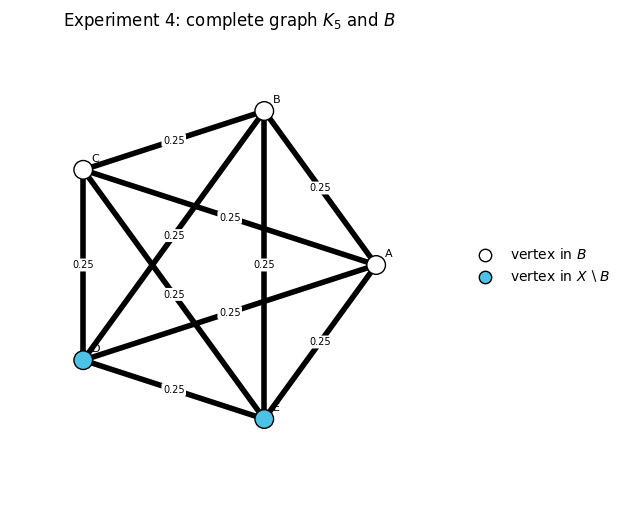

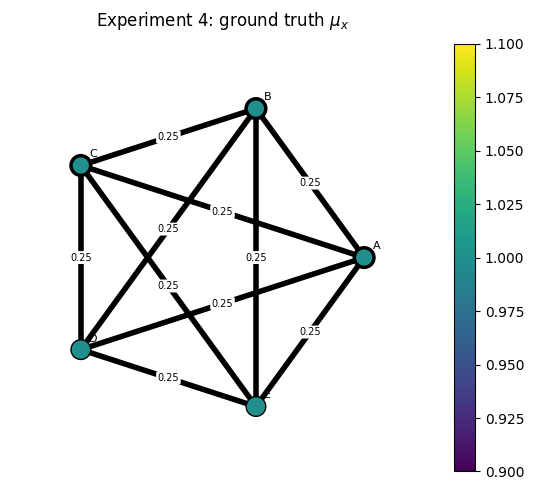

In [7]:
from itertools import combinations

vertices4 = ["A", "B", "C", "D", "E"]
edges4 = list(combinations(vertices4, 2))  # every pair: K_5
B4_labels = ["A", "B", "C"]  # ceil(|X| / 2) observed vertices
G4 = Graph(vertices4, edges4, B4_labels, w=0.25, mu="constant", mu_val=1.0)
W4, mu4, B4 = G4.W, G4.mu, G4.B
P4 = G4.transition_matrix()
T4 = len(vertices4) + 1
t_max4 = 2 * T4 - 1
print(f"|X| = {G4.n}, |E| = {len(G4.edges)}, |B| = {len(B4)}, T = {T4}")

plot_general_graph(G4, title="Experiment 4: complete graph $K_5$ and $B$")
plot_general_graph(G4, values=mu4, title=r"Experiment 4: ground truth $\mu_x$")
plt.show()

data shape (2T-1, |B|, |B|): (11, 3, 3)
FRNE = 0.797382%
check r(1, y, y) = p_yy: True
probability mass observed by t = 2T-1 (exact):
 [[0.9437 0.9578 0.9578]
 [0.9578 0.9437 0.9578]
 [0.9578 0.9578 0.9437]]
probability mass observed by t = 2T-1 (empirical):
 [[0.945  0.9573 0.9575]
 [0.9587 0.9441 0.9588]
 [0.958  0.9582 0.9421]]


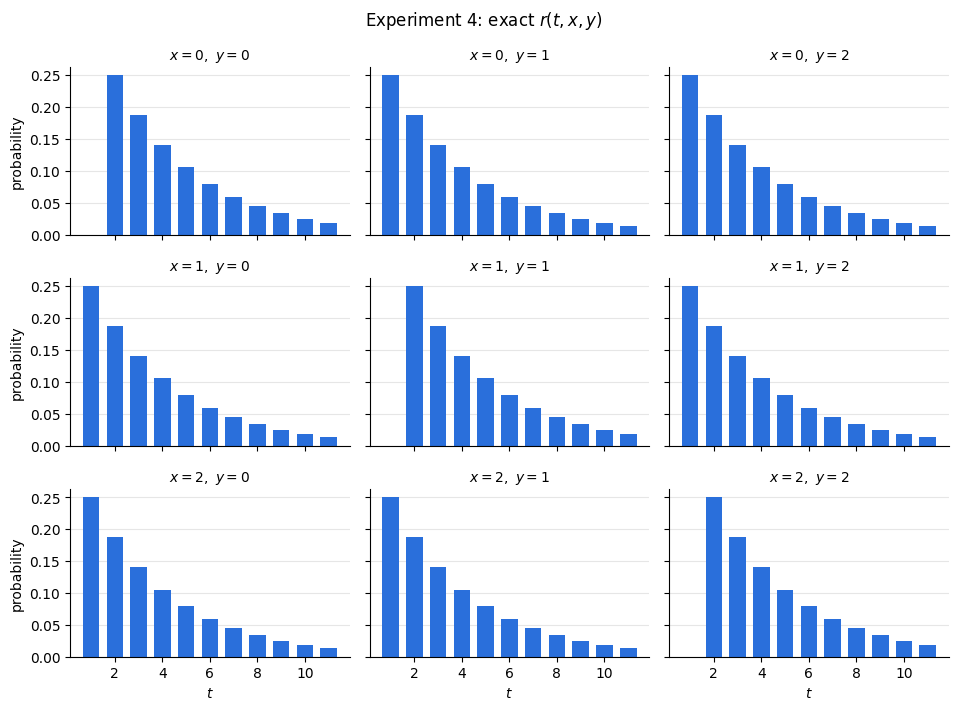

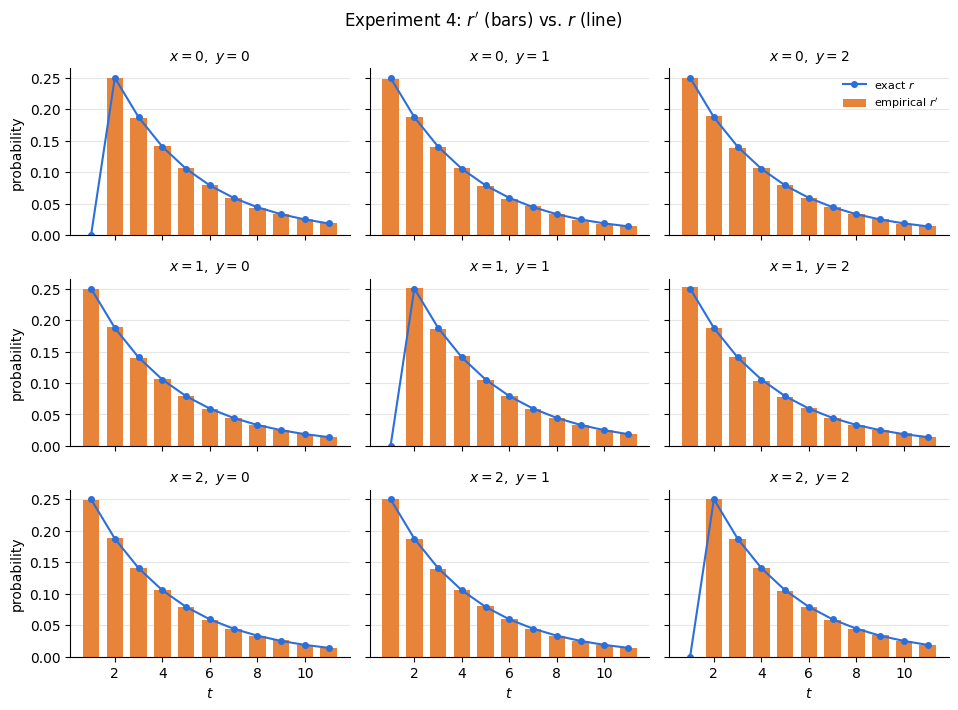

In [8]:
r4 = exact_first_passage_literal(P4, B4, t_max4)
r4_emp = empirical_first_passage(P4, B4, t_max4, n_walks=10**5, seed=0)
summarize(P4, B4, r4_emp, r4)

plot_exact_distribution(r4, B4, title="Experiment 4: exact $r(t, x, y)$")
plot_empirical_distribution(r4_emp, B4, r=r4,
                            title="Experiment 4: $r'$ (bars) vs. $r$ (line)")
plt.show()

### Experiment 4: varying $T$ on $K_5$

Keep $|B|=\lceil |X|/2\rceil=3$ fixed. For every integer $T$ with $|X|<T<200$, calculate FRNE using first-passage data through $t=2T-1$. A single Monte Carlo run at the largest horizon is reused for each prefix, keeping the comparisons efficient and consistent. Increase `N4_T_sweep` to reduce Monte Carlo noise.

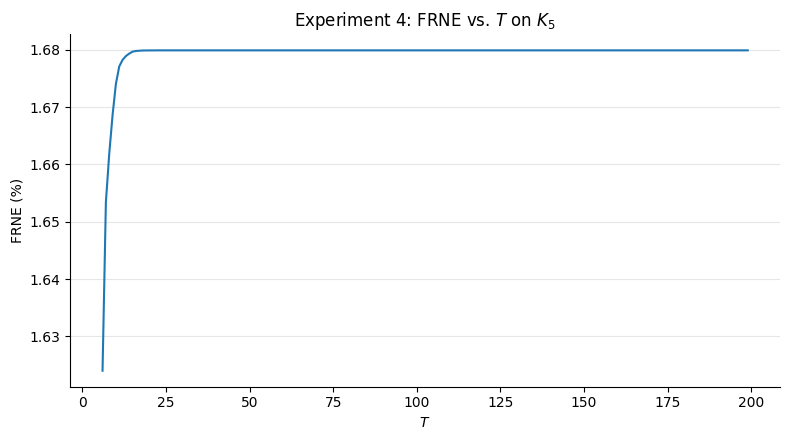

In [9]:
N4_T_sweep = 20_000
seed4_T_sweep = 400
T4_values = list(range(G4.n + 1, 200))
B4_T = torch.tensor([G4.index[v] for v in B4_labels], dtype=torch.long)
t_max4_sweep = 2 * T4_values[-1] - 1
r4_exact_sweep = exact_first_passage_literal(P4, B4_T, t_max4_sweep)
r4_emp_sweep = empirical_first_passage(
    P4, B4_T, t_max4_sweep, n_walks=N4_T_sweep,
    batch=10_000, seed=seed4_T_sweep
)
FRNE4_by_T = [
    frne(r4_exact_sweep[:2 * T - 1], r4_emp_sweep[:2 * T - 1])
    for T in T4_values
]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(T4_values, FRNE4_by_T, lw=1.5)
ax.set(xlabel="$T$", ylabel="FRNE (%)",
       title="Experiment 4: FRNE vs. $T$ on $K_5$")
ax.grid(axis="y", color="0.9")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Experiment 5: the complete bipartite graph $K_{3,3}$

$K_{3,3}$ has two vertex classes of size three and all nine possible cross-edges; it is a standard non-planar graph. We observe the left class, use unit edge weights and $\mu_x=\deg(x)=3$, so the walk has no holding probability. The six-vertex graph uses $T=6$ and first-passage data through $t=2T-1=11$.

K_{3,3}: |X| = 6, |E| = 9, |B| = 3, T = 6, t_max = 11
mu: [3.0, 3.0, 3.0, 3.0, 3.0, 3.0]
p_xx: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


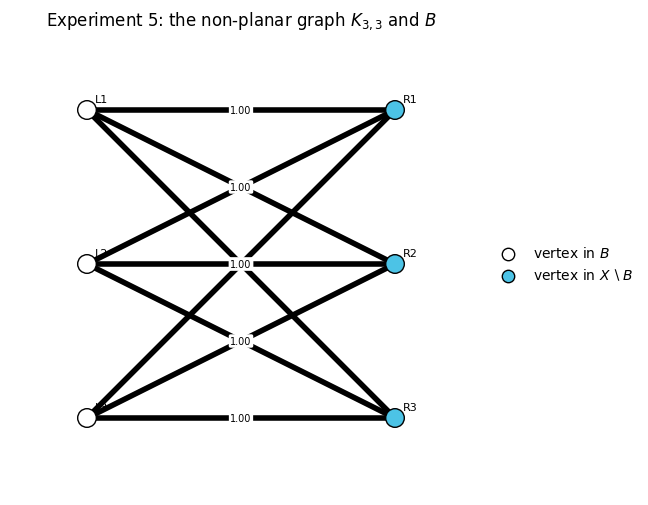

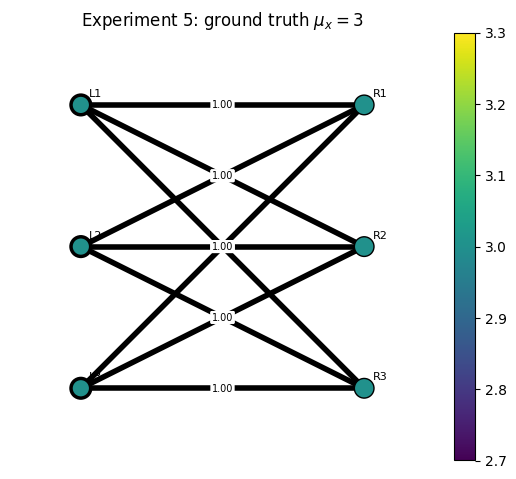

In [10]:
from itertools import product

left3 = ["L1", "L2", "L3"]
right3 = ["R1", "R2", "R3"]
vertices5 = left3 + right3
edges5 = list(product(left3, right3))
B5_labels = left3.copy()
positions5 = {
    "L1": (-1, 1), "L2": (-1, 0), "L3": (-1, -1),
    "R1": (1, 1), "R2": (1, 0), "R3": (1, -1),
}
G5 = Graph(vertices5, edges5, B5_labels, w=1.0, mu="deg")
W5, mu5, B5 = G5.W, G5.mu, G5.B
P5 = G5.transition_matrix()
T5 = G5.n
t_max5 = 2 * T5 - 1
print(f"K_{{3,3}}: |X| = {G5.n}, |E| = {len(G5.edges)}, "
      f"|B| = {len(B5)}, T = {T5}, t_max = {t_max5}")
print("mu:", mu5.tolist())
print("p_xx:", torch.diagonal(P5).tolist())

plot_general_graph(G5, title="Experiment 5: the non-planar graph $K_{3,3}$ and $B$",
                  positions=positions5)
plot_general_graph(G5, values=mu5, title=r"Experiment 5: ground truth $\mu_x=3$",
                  positions=positions5)
plt.show()

data shape (2T-1, |B|, |B|): (11, 3, 3)
FRNE = 0.569758%
check r(1, y, y) = p_yy: True
probability mass observed by t = 2T-1 (exact):
 [[0.8683 0.8683 0.8683]
 [0.8683 0.8683 0.8683]
 [0.8683 0.8683 0.8683]]
probability mass observed by t = 2T-1 (empirical):
 [[0.8681 0.8678 0.8679]
 [0.869  0.8695 0.8678]
 [0.8676 0.8675 0.8689]]


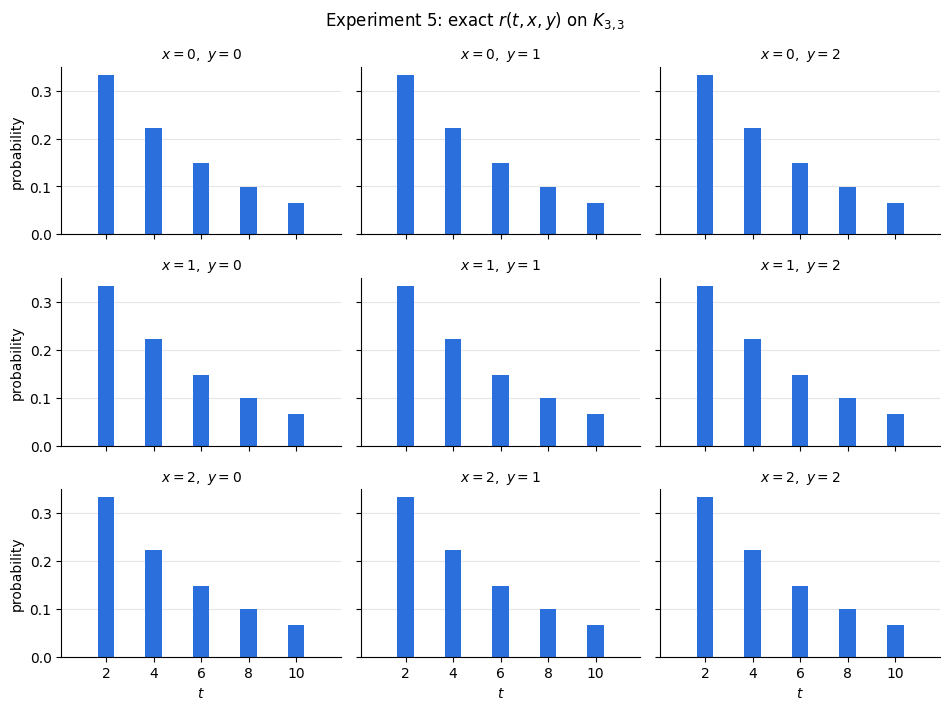

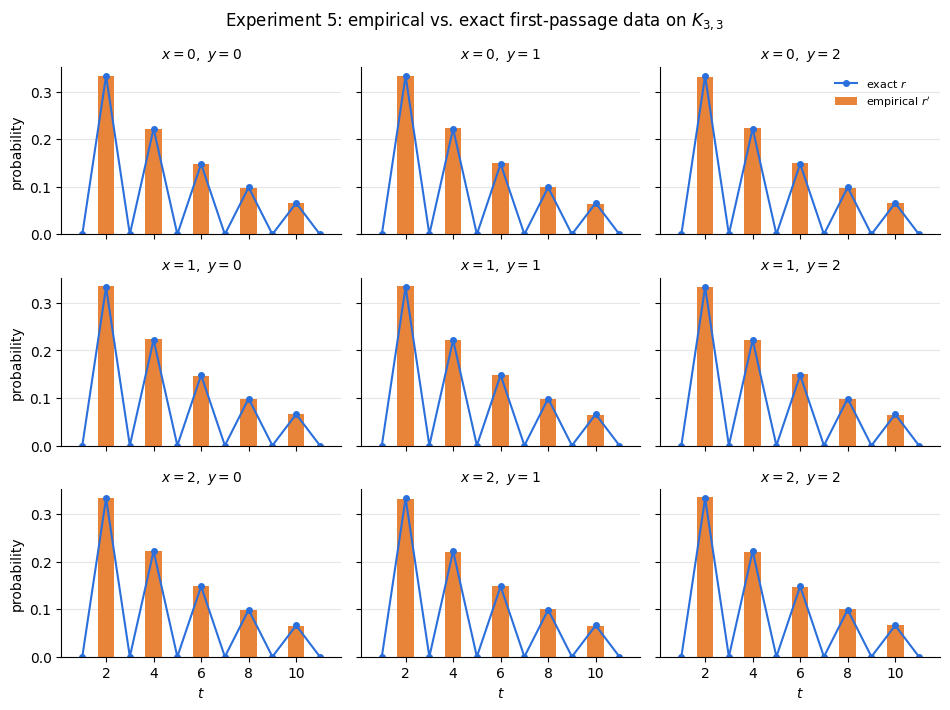

In [11]:
N5 = 10**5
seed5 = 0
r5 = exact_first_passage_literal(P5, B5, t_max5)
r5_emp = empirical_first_passage(P5, B5, t_max5, n_walks=N5, seed=seed5)
summarize(P5, B5, r5_emp, r5)

plot_exact_distribution(r5, B5, title="Experiment 5: exact $r(t, x, y)$ on $K_{3,3}$")
plot_empirical_distribution(r5_emp, B5, r=r5,
                            title="Experiment 5: empirical vs. exact first-passage data on $K_{3,3}$")
plt.show()

### Experiment 5: varying $T$ on $K_{3,3}$

Keep the left partition as $B$, so $|B|=3=\lceil |X|/2\rceil$. For every integer $T$ with $|X|<T<200$, calculate FRNE through $t=2T-1$. One Monte Carlo run at the maximum horizon supplies each prefix. Increase `N5_T_sweep` to reduce Monte Carlo noise.

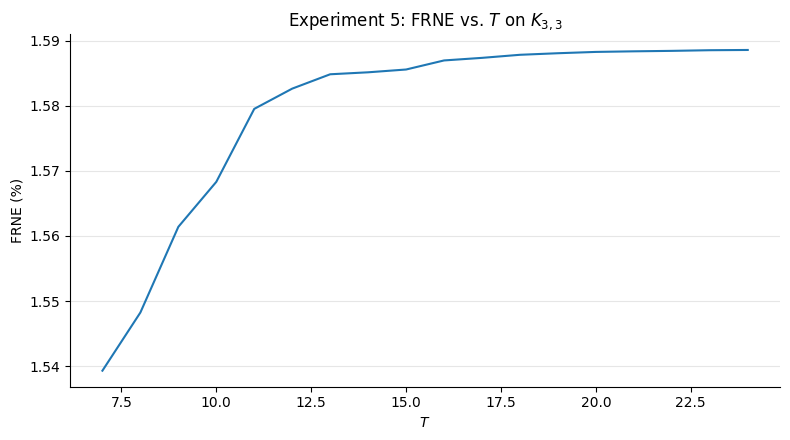

In [13]:
N5_T_sweep = 20_000
seed5_T_sweep = 500
T5_values = list(range(G5.n + 1, 25))
t_max5_sweep = 2 * T5_values[-1] - 1
r5_exact_sweep = exact_first_passage_literal(P5, B5, t_max5_sweep)
r5_emp_sweep = empirical_first_passage(
    P5, B5, t_max5_sweep, n_walks=N5_T_sweep,
    batch=10_000, seed=seed5_T_sweep
)
FRNE5_by_T = [
    frne(r5_exact_sweep[:2 * T - 1], r5_emp_sweep[:2 * T - 1])
    for T in T5_values
]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(T5_values, FRNE5_by_T, lw=1.5)
ax.set(xlabel="$T$", ylabel="FRNE (%)",
       title="Experiment 5: FRNE vs. $T$ on $K_{3,3}$")
ax.grid(axis="y", color="0.9")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()